# 08B.3 — Robustness, detectability and permutation diagnostics

**Question.** Is any apparent football-transfer gain credible, and is the study able to see a useful difference at all?

1. **Declared sensitivity analyses** — position (WR-only refit), alternative outcome definitions (context-conditioned, targeted-only, non-targeted-only), exposure rules, first NFL season, an alternative learner. Each is a full refit on its own cohort with the same folds. **None may replace the primary analysis**: they say whether its reading depends on a choice. The definition with the best result is never promoted.
2. **Planted-signal simulation** — the Milestone 07C machinery on the *real* football cohort: athlete count, position mix, folds, collinearity of each tracking block with official testing, and the real residual noise. Outputs: power against the true effect, the false-positive rate, interval coverage, the smallest detectable effect, and cohort-size scenarios. Bounded budget, checkpointed, with iteration-level progress.
3. **Permutation diagnostics** — the refit-based null distributions of 08B.2.
4. **Robustness reading** — point estimate, statistical evidence, practical importance, cohort limits, measurement reliability and outcome validity, kept apart.

A positive but highly uncertain result is exploratory.

**Gate.** Needs the registry branch of 08B.0 and an executed 08B.2 with the same registry.

**Prerequisites (same `RUN_MODE`).** as 08B.2, plus 08B.2.

In [1]:
RUN_MODE = 'full'             # 'smoke' | 'full'
SEED = 20261011
FORCE_REBUILD = False         # True = recompute the sensitivities and RESTART the simulation checkpoint of this configuration
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
EXPERIMENT_VERSION = '08B3.1'
REGISTRY_VERSION = 'v1'
BOOTSTRAP_ITERATIONS = 2000   # sensitivity analyses
SIM_REPLICATES = 200          # synthetic targets per scenario on the real cohort
SIM_BOOTSTRAP = 300           # paired bootstrap inside each replicate
SIM_SAMPLE_REPLICATES = 100   # per cohort-size scenario
SIM_CANDIDATES = ('M2', 'M5')  # the registered primary and secondary models
RESUME_MODE = 'resume'        # 'resume' | 'restart' | 'require_complete'
MAX_SECONDS = None            # stop the simulation cleanly after this many seconds (checkpoint kept)
SHOW_TABLES = True

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

from dataclasses import replace

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import atlas as at
from nflbdb.research.advanced_movement import checkpoint as ck
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import data as amd
from nflbdb.research.advanced_movement import football_figures as ff
from nflbdb.research.advanced_movement import football_registry as fr
from nflbdb.research.advanced_movement import football_reliability as frl
from nflbdb.research.advanced_movement import football_transfer as ft
from nflbdb.research.advanced_movement import opportunity_validation as ov
from nflbdb.research.advanced_movement import transfer as tr
from nflbdb.research.advanced_movement import transfer_models as tm
from nflbdb.research.advanced_movement import transfer_power as tp
from nflbdb.research.advanced_movement.artifacts import FootballStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
acfg = amc.AdvancedConfig().for_mode(controls)
ftc = ft.FootballTransferConfig().for_mode(controls)
if not controls.smoke:
    ftc = replace(ftc, n_boot=BOOTSTRAP_ITERATIONS)
tc = ftc.transfer_config(tr.TransferConfig().for_mode(controls))
store = FootballStore(cfg, controls)
up, T = store.upstream, store.transfer
amc.seed_everything(controls.seed)
NB = {'00': '00_research_setup_and_data_audit.ipynb', '02': '02_functional_pca_baseline.ipynb', '06A': '06a_transfer_cohort_and_leakage_audit.ipynb',
      '06B': '06b_combine_to_nfl_transfer_benchmark.ipynb', '08B1': '08b1_football_outcome_reliability.ipynb',
      '08B2': '08b2_football_transfer_benchmark.ipynb', '08B3': '08b3_transfer_robustness_and_detectability.ipynb'}

# ---- GATES: registry branch, and an executed 08B.2 on the same registry
REGISTRY, BRANCH = fr.require_branch(store, REGISTRY_VERSION)
m2 = store.read_json('football_transfer_manifest', NB['08B2'])
if m2.get('registry_hash') != REGISTRY['version_hash']:
    raise fr.FootballTransferBlocked('notebook 08B.2 was executed with another registry: rerun 08B.2 first')
PRIMARY, HYP = m2['primary'], REGISTRY['hypotheses']
P0, P1 = HYP['primary']
vc = ov.ValidationConfig(**{k: (tuple(v) if isinstance(v, list) else v) for k, v in REGISTRY['config'].items() if k != 'validation_version'})

# ---- Milestone 06 hand-over (as in 08B.2)
registry_m05, freeze_audit = tr.audit_freeze(store.nfl, controls.run_mode)
tr.assert_frozen(freeze_audit)
folds = T.require(tr.FOLDS, NB['06A'])
audit = tr.require_audit(T, registry_m05, folds)
assert audit['folds_hash'] == m2['folds_hash'], 'the Milestone 06 folds changed since 08B.2 was executed'
design_columns = T.read_json(tr.INPUT_CONTRACT, NB['06A'])['design_columns']
athletes = up.require(amd.ATHLETES, NB['00'])
windows = up.require(ck.WINDOWS, NB['02'])
mart = amd.AdvInputs(cfg, acfg).mart().filter(pl.col('nfl_id').is_in(athletes['nfl_id'].to_list()))
official = at.official_table(mart, athletes)
ORDER = dict(zip(windows['seq_id'].to_list(), windows['attempt_order'].to_list()))
attempts = T.require_named('transfer_attempt_representations_outer', NB['06B'])
blocks = tm.RepBlocks(attempts, ORDER, scheme='outer', how=tc.aggregation)
support06 = T.require(tm.SUPPORT, NB['06B'])
design = tm.Design.build(folds, official, design_columns).keep_ids(support06.filter(pl.col('in_paired_cohort'))['nfl_id'].to_list())

# ---- 08B.1 rows and 08B.2 results (read only)
rows_all = store.require(frl.ROWS, NB['08B1'])
oof = store.require(ft.OOF, NB['08B2'])
paired = store.require(ft.PAIRED, NB['08B2'])
hyp_table = store.require(ft.HYP, NB['08B2'])
perm, perm_draws = store.require(ft.PERM, NB['08B2']), store.require(ft.PERM_DRAWS, NB['08B2'])
MODELS = ft.ladder(tc, ftc)
REGISTERED = [(m, r) for role, m, r in ft.registered_pairs(HYP) if role in ('primary', 'secondary')]
LAB = ft.FootballLabels(frl.rows_of(rows_all, PRIMARY), PRIMARY, vc)
DD = ft.football_design(design, LAB)
assert DD.n == m2['n_primary'], f'{DD.n} athletes rebuilt, {m2["n_primary"]} in the 08B.2 primary cohort'

PARAMS = {'experiment_version': EXPERIMENT_VERSION, 'registry_hash': REGISTRY['version_hash'], 'folds_hash': audit['folds_hash'], 'football': ftc.params(),
          'primary': PRIMARY, 'hypotheses': HYP}
PROV = {'notebook': NB['08B3'], **PARAMS, 'run_mode': controls.run_mode, 'seed': controls.seed, 'branch': BRANCH['name'], 'evidence_label': BRANCH['label']}
save = lambda df, c: store.write(df, c, '08B3', PROV) if controls.save_tables else df
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · **{BRANCH["label"]}** · primary `{PRIMARY}` · {DD.n} athletes ({m2["position_counts"]}) · '
                 f'primary comparison {P0} versus {P1} · 08B.2 Gate C: {m2["gate_c"]}'))

**Run mode: `full`** (FULL) · **EXPLORATORY — source semantics inferred; definitions locked** · primary `FO01.S0` · 84 athletes (TE 20 · WR 64) · primary comparison M2 versus M1 · 08B.2 Gate C: PASS

## 1 · Declared sensitivity analyses

| Analysis | What changes | Why it is only a sensitivity |
|---|---|---|
| `position:WR:refit` | WR athletes only, models refitted | fewer athletes; no independent TE model is attempted (about 24 linked TE) |
| `definition:context (route × alignment)` | label = separation minus the expected value of the route × alignment cell, **cross-fitted on the training athletes of each fold** | removes route mix and NFL role: a different estimand |
| `definition:targeted_only` / `not_targeted_only` | rows selected by target status | the quarterback's choice depends on the outcome |
| `exposure:min_games_8`, `exposure:min_obs_40` | stricter support rule | changes who is in the cohort |
| `season:first` | only the athlete's first observed NFL season | a common post-draft horizon |
| `learner:elastic_net` | another regularised learner | same data |

The plan is fixed in the cell below before anything is fitted. An analysis whose cohort is too small is reported as *not evaluated*.

23:31:28 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:08b3_sensitivity] restored from cache (current)


declared plan: ['position:WR:refit', 'definition:context (route × alignment)', 'exposure:min_games_8', 'exposure:min_obs_40', 'season:first', 'learner:elastic_net', 'definition:targeted_only', 'definition:not_targeted_only']


analysis,kind,target_id,label_kind,n_athletes,position_counts,evaluated,note
str,str,str,str,i64,str,bool,str
"""position:WR:refit""","""position""","""FO01.S0""","""observed""",64,"""WR 64""",true,"""WR athletes only, refitted"""
"""definition:context (route × alignment)""","""definition""","""FO01.S0|route_x_alignment""","""cross_fitted""",84,"""TE 20 · WR 64""",true,"""cross-fitted cell residual: context means from the training athletes of each fold"""
"""exposure:min_games_8""","""exposure""","""FO01.S0""","""observed""",83,"""TE 20 · WR 63""",true,"""support rule: twice the games"""
"""exposure:min_obs_40""","""exposure""","""FO01.S0""","""observed""",84,"""TE 20 · WR 64""",true,"""support rule: twice the observations"""
"""season:first""","""season""","""FO01.S0""","""observed""",78,"""TE 18 · WR 60""",true,"""first observed NFL season only"""
"""learner:elastic_net""","""learner""","""FO01.S0""","""observed""",84,"""TE 20 · WR 64""",true,"""elastic net instead of ridge"""
"""definition:targeted_only""","""definition""","""FO01.S0T""","""observed""",68,"""TE 15 · WR 53""",true,"""rows selected by target status (outcome-dependent)"""
"""definition:not_targeted_only""","""definition""","""FO01.S0N""","""observed""",84,"""TE 20 · WR 64""",true,"""rows selected by target status (outcome-dependent)"""


analysis,target_id,n_athletes,estimate,ci_lower,ci_upper,relative,established,worse
str,str,i64,f64,f64,f64,f64,bool,bool
"""PRIMARY ANALYSIS""","""FO01.S0""",84,-0.000685,-0.00931,0.008171,-0.001807,false,false
"""position:WR:refit""","""FO01.S0""",64,-0.001874,-0.003445,-0.000468,-0.00488,false,true
"""definition:context (route × alignment)""","""FO01.S0|route_x_alignment""",84,-0.000334,-0.001242,0.00047,-0.001298,false,false
"""exposure:min_games_8""","""FO01.S0""",83,-0.000516,-0.008654,0.008005,-0.00135,false,false
"""exposure:min_obs_40""","""FO01.S0""",84,-0.000685,-0.0089,0.00787,-0.001807,false,false
"""season:first""","""FO01.S0""",78,-0.000525,-0.001338,0.000104,-0.001198,false,false
"""learner:elastic_net""","""FO01.S0""",84,0.000007,-0.000196,0.000221,0.000019,false,false
"""definition:targeted_only""","""FO01.S0T""",68,-0.001226,-0.003043,0.000476,-0.001847,false,false
"""definition:not_targeted_only""","""FO01.S0N""",84,0.000555,-0.006002,0.007753,0.001686,false,false


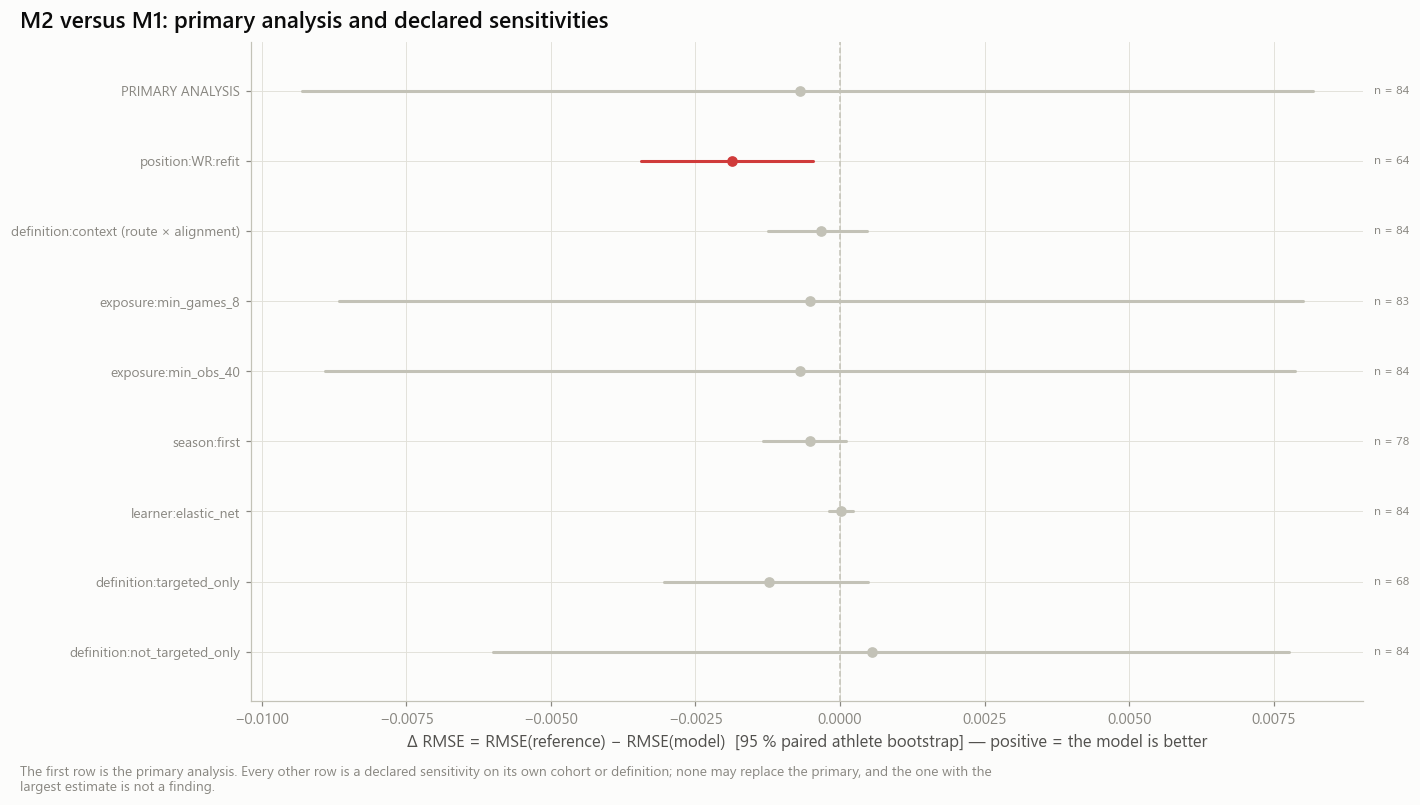

In [3]:
rows_p = frl.rows_of(rows_all, PRIMARY)
first = rows_p.group_by('nfl_id').agg(pl.col('season').min().alias('_s'))
rows_first = rows_p.join(first, on='nfl_id').filter(pl.col('season') == pl.col('_s')).drop('_s')
ITEMS = [
    {'analysis': 'position:WR:refit', 'kind': 'position', 'labels': LAB, 'design': design.subset(design.position == 'WR'), 'note': 'WR athletes only, refitted'},
    {'analysis': 'exposure:min_games_8', 'kind': 'exposure', 'labels': ft.FootballLabels(rows_p, PRIMARY, replace(vc, min_games=max(vc.min_games, 2 * vc.min_games))), 'design': design,
     'note': 'support rule: twice the games'},
    {'analysis': 'exposure:min_obs_40', 'kind': 'exposure', 'labels': ft.FootballLabels(rows_p, PRIMARY, replace(vc, min_obs=2 * vc.min_obs)), 'design': design,
     'note': 'support rule: twice the observations'},
    {'analysis': 'season:first', 'kind': 'season', 'labels': ft.FootballLabels(rows_first, PRIMARY, vc), 'design': design, 'note': 'first observed NFL season only'},
    {'analysis': 'learner:elastic_net', 'kind': 'learner', 'labels': LAB, 'design': design, 'learner': 'enet', 'note': 'elastic net instead of ridge'},
]
if PRIMARY.startswith('FO01'):
    ITEMS.insert(1, {'analysis': 'definition:context (route × alignment)', 'kind': 'definition',
                     'labels': ft.FootballLabels(rows_p, PRIMARY + '|route_x_alignment', vc, 'cell_residual', ('route', 'alignment')), 'design': design,
                     'note': 'cross-fitted cell residual: context means from the training athletes of each fold'})
    for key, name in (('FO01.S0T', 'definition:targeted_only'), ('FO01.S0N', 'definition:not_targeted_only')):
        r = frl.rows_of(rows_all, key)
        if r.height:
            ITEMS.append({'analysis': name, 'kind': 'definition', 'labels': ft.FootballLabels(r, key, vc), 'design': design, 'note': 'rows selected by target status (outcome-dependent)'})
print('declared plan:', [it['analysis'] for it in ITEMS])

CONTRACTS = [ft.SENS, ft.OOF_SENS, ft.PERF_SENS, ft.PAIRED_SENS]
sens = store.build('08b3_sensitivity', CONTRACTS, lambda: ft.run_sensitivities(ITEMS, blocks, MODELS, REGISTERED, tc, ftc, controls.seed),
                   {**PARAMS, 'plan': [it['analysis'] for it in ITEMS]}, [store.parquet(frl.ROWS), T.parquet(tr.FOLDS)])
plan, paired_sens = sens[ft.SENS.name], sens[ft.PAIRED_SENS.name]
ref_row = paired.filter((pl.col('analysis') == ft.ANALYSIS) & (pl.col('target_id') == PRIMARY) & (pl.col('metric') == 'delta_rmse') & (pl.col('model') == P0) & (pl.col('reference') == P1))
forest = pl.concat([ref_row.with_columns(pl.lit('PRIMARY ANALYSIS').alias('analysis')),
                    paired_sens.filter((pl.col('metric') == 'delta_rmse') & (pl.col('model') == P0) & (pl.col('reference') == P1))])
with pl.Config(tbl_rows=-1, tbl_width_chars=240, fmt_str_lengths=120):
    display(plan)
    display(forest.select('analysis', 'target_id', 'n_athletes', 'estimate', 'ci_lower', 'ci_upper', 'relative', 'established', 'worse'))
store.show(ff.fig_paired_forest(forest.rename({'estimate': 'delta_rmse'}), f'{P0} versus {P1}: primary analysis and declared sensitivities', ('analysis',),
                                caption='The first row is the primary analysis. Every other row is a declared sensitivity on its own cohort or definition; none may replace the '
                                        'primary, and the one with the largest estimate is not a finding.'),
           'AM08B3_01_sensitivity_forest', {'sensitivities': forest}, publication=True, source='football_transfer_sensitivity_comparisons', n='athletes per analysis (annotated)')

## 2 · Planted-signal simulation on the real football cohort

Synthetic target of one replicate: the real M1 out-of-fold prediction, plus position-wise residual noise resampled from the real M1 residuals, plus a planted share **f** of the residual variance carried by the leading direction of the candidate block (*conditional* = after removing what official testing explains of that direction; *raw* = as it is). The benchmark pipeline and its criterion (95 % paired bootstrap interval above 0) are then applied unchanged.

- **f = 0** gives the false-positive rate of the whole pipeline.
- The **power curve** gives the smallest planted effect detected 80 % of the time.
- **Cohort-size scenarios** resample the observed athletes to larger cohorts: sampling precision only, not an inductive evaluation.

The simulation is checkpointed by a configuration hash. Interrupting loses at most a few replicates: **rerun the cell to resume**. An incomplete simulation is never summarised.

In [4]:
# ============================================================
# WINDOWS CHECKPOINT FIX — RUN ONCE BEFORE SIMULATION
# ============================================================

from pathlib import Path
import time
import polars as pl

def windows_safe_checkpoint(path, rows):
    """
    Save simulation checkpoint without Path.replace().

    WARNING:
    Direct writes are not atomic. Preserve a valid backup first.
    """
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    # Prefer direct writing when Windows blocks atomic replacement.
    for attempt in range(5):
        try:
            rows.write_parquet(path)
            print(
                f"[CHECKPOINT] Saved {rows.height:,} rows → {path.name}",
                flush=True,
            )
            return

        except PermissionError as exc:
            if attempt == 4:
                raise

            print(
                f"[CHECKPOINT] File locked, retry {attempt + 1}/5",
                flush=True,
            )
            time.sleep(1.0 * (attempt + 1))


# Patch the imported module function.
tp._write_checkpoint = windows_safe_checkpoint

print("Windows checkpoint workaround installed.")

Windows checkpoint workaround installed.


In [8]:
# ================================================================
# NFL BIG DATA BOWL 2027 — MILESTONE 08B.3
# COMPLETE POWER SIMULATION CELL
#
# LOAD → VALIDATE → RECOVER → RESUME → SUMMARIZE → SAVE → PLOT
#
# Dependencies already defined in the notebook:
# controls, DD, oof, blocks, tc, PRIMARY, ft, tp, ff,
# SIM_CANDIDATES, SIM_REPLICATES, SIM_BOOTSTRAP,
# SIM_SAMPLE_REPLICATES, store, m2, PROV
# ================================================================

from pathlib import Path
from datetime import datetime
from IPython.display import display, Markdown
import os
import time
import uuid
import shutil
import json
import numpy as np
import polars as pl


# ================================================================
# 0. USER CONTROLS
# ================================================================

RUN_SIMULATION = True
LOAD_SAVED = True
RESTART_FROM_ZERO = False

# None = run until all scenarios finish.
MAX_RUNTIME_SECONDS = None

# Existing filenames used in previous notebook versions.
SEARCH_LEGACY = True

# Number of retries for transient Windows file locks.
WRITE_RETRIES = 6
WRITE_RETRY_DELAY = 0.5

DISPLAY_ROWS = 20


def log(message):
    print(
        f"[{datetime.now():%H:%M:%S}] {message}",
        flush=True
    )


# ================================================================
# 1. BUILD SIMULATION CONFIGURATION
# ================================================================

pc = ft.power_config(
    controls,
    DD.n,
    SIM_CANDIDATES,
    SIM_REPLICATES,
    SIM_BOOTSTRAP,
    SIM_SAMPLE_REPLICATES,
)

st = ft.power_structure(
    DD,
    oof,
    blocks,
    tc,
    pc,
    PRIMARY,
)

sim_plan = tp.scenario_plan(pc, DD.n)

CONFIG_HASH = str(tp.config_hash(pc, tc, st))
N_PLANNED = int(sim_plan["replicates"].sum())

CHECKPOINT_DIR = Path(store.checkpoints_dir)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

SIM_CHECKPOINT = (
    CHECKPOINT_DIR
    / f"football_power_replicates_{CONFIG_HASH[:12]}.parquet"
)

print("=" * 75)
print("FOOTBALL TRANSFER POWER SIMULATION")
print("=" * 75)

display(Markdown(
    f"""
### Simulation configuration

| Parameter | Value |
|---|---|
| Scenarios | {sim_plan.height} |
| Planned replicates | {N_PLANNED:,} |
| Outer folds | {np.unique(DD.fold).size} |
| Ridge penalties | {tc.alphas.size} |
| Inner folds | {tc.inner_folds} |
| Bootstrap samples | {pc.n_boot} |
| M1 residual RMSE | {st.rmse_m1:.4f} |
| Configuration hash | `{CONFIG_HASH}` |
| Active checkpoint | `{SIM_CHECKPOINT.name}` |
"""
))

print(
    "Planted-direction redundancy R²:",
    ", ".join(
        f"{k}={v:.3f}"
        for k, v in st.redundancy.items()
    ),
)


# ================================================================
# 2. WINDOWS-SAFE CHECKPOINT WRITER
#
# IMPORTANT:
# The original implementation failed at:
#     tmp.replace(path)
#
# This implementation preserves previous checkpoints and creates
# recoverable unique files if Windows blocks replacement.
# ================================================================

def windows_safe_checkpoint(path, rows):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    temp = path.with_name(
        f"{path.stem}.{uuid.uuid4().hex}.tmp.parquet"
    )

    rows.write_parquet(temp)

    for attempt in range(WRITE_RETRIES):
        try:
            os.replace(temp, path)

            log(
                f"CHECKPOINT: {rows.height:,} rows saved "
                f"to {path.name}"
            )
            return

        except PermissionError as exc:
            if attempt + 1 < WRITE_RETRIES:
                time.sleep(
                    WRITE_RETRY_DELAY * (attempt + 1)
                )
                continue

            # Keep the temporary checkpoint for recovery.
            raise PermissionError(
                "Windows refused checkpoint replacement.\n"
                f"Destination: {path}\n"
                f"Recovered data file: {temp}\n"
                f"Original error: {exc}"
            ) from exc


tp._write_checkpoint = windows_safe_checkpoint


# ================================================================
# 3. DISCOVER SAVED CHECKPOINTS
# ================================================================

def saved_candidates():
    candidates = [SIM_CHECKPOINT]

    if SEARCH_LEGACY:
        candidates.extend([
            CHECKPOINT_DIR / "football_power_replicates.parquet",
            CHECKPOINT_DIR
            / f"football_power_replicates_{CONFIG_HASH[:12]}_safe.parquet",
        ])

        candidates.extend(
            CHECKPOINT_DIR.glob(
                "football_power_replicates*.tmp.parquet"
            )
        )

    unique = []
    seen = set()

    for path in candidates:
        path = Path(path)

        if path.exists() and str(path) not in seen:
            unique.append(path)
            seen.add(str(path))

    return unique


def read_candidate(path):
    try:
        df = pl.read_parquet(path)

        log(
            f"FOUND: {path.name} — "
            f"{df.height:,} rows"
        )

        return df

    except Exception as exc:
        log(
            f"UNREADABLE: {path.name} — "
            f"{type(exc).__name__}: {exc}"
        )
        return None


def schema_compatible(df):
    if df is None or df.is_empty():
        return False

    expected_columns = set(tp.REPLICATES.columns)

    if not expected_columns.issubset(set(df.columns)):
        return False

    # Check config hash when stored in the checkpoint.
    if "config_hash" in df.columns:
        hashes = set(
            df["config_hash"]
            .drop_nulls()
            .unique()
            .to_list()
        )
        return hashes == {CONFIG_HASH}

    # Without a hash or independently verified provenance,
    # a legacy checkpoint cannot be accepted automatically.
    return False


SAVED_PATH = None
SAVED_REPS = None

if LOAD_SAVED:
    for path in saved_candidates():
        candidate = read_candidate(path)

        if schema_compatible(candidate):
            if (
                SAVED_REPS is None
                or candidate.height > SAVED_REPS.height
            ):
                SAVED_PATH = path
                SAVED_REPS = candidate
        elif candidate is not None:
            log(
                f"SKIPPED: {path.name} — "
                "configuration compatibility not established"
            )


# ================================================================
# 4. RECOVER CHECKPOINT TO ACTIVE PATH
# ================================================================

if SAVED_REPS is not None:
    log(
        f"Compatible saved results: "
        f"{SAVED_REPS.height:,} rows in {SAVED_PATH.name}"
    )

    if (
        SAVED_PATH != SIM_CHECKPOINT
        and not SIM_CHECKPOINT.exists()
    ):
        # Preserve original. Copy only a verified compatible file.
        shutil.copy2(SAVED_PATH, SIM_CHECKPOINT)
        log(
            f"Recovered checkpoint to {SIM_CHECKPOINT.name}"
        )

else:
    log(
        "No automatically verified checkpoint found. "
        "Existing legacy files remain untouched."
    )


# ================================================================
# 5. RUN / RESUME USING NATIVE VALIDATION
# ================================================================

reps = None
sim_summary = None

if RUN_SIMULATION:
    resume_mode = (
        "restart" if RESTART_FROM_ZERO else "resume"
    )

    log(
        f"Starting simulation: {resume_mode}"
    )

    start_time = time.perf_counter()

    reps, sim_summary = tp.run_simulation(
        st,
        blocks,
        tc,
        pc,
        SIM_CHECKPOINT,
        resume_mode=resume_mode,
        save=controls.save_tables,
        max_seconds=MAX_RUNTIME_SECONDS,
    )

    log(
        "Simulation returned after "
        f"{(time.perf_counter() - start_time) / 60:.2f} min"
    )

else:
    if SAVED_REPS is not None:
        reps = SAVED_REPS

    log(
        "Inspection-only mode: no simulation was executed."
    )


# ================================================================
# 6. REPORT REAL SIMULATION STATUS
# ================================================================

print("\n" + "=" * 75)
print("SIMULATION STATUS")
print("=" * 75)

if isinstance(reps, pl.DataFrame):
    print(f"Replicate rows: {reps.height:,}")
    print(f"Planned replicates: {N_PLANNED:,}")
    display(reps.head(DISPLAY_ROWS))
else:
    print("No validated replicate results returned.")

if isinstance(sim_summary, dict):
    print("\nNative simulation status:")
    for key, value in sim_summary.items():
        if isinstance(value, (bool, str, int, float, type(None))):
            print(f"{key}: {value}")
else:
    print(
        "Native completion summary unavailable "
        "(inspection-only mode)."
    )

FOOTBALL TRANSFER POWER SIMULATION



### Simulation configuration

| Parameter | Value |
|---|---|
| Scenarios | 44 |
| Planned replicates | 6,800 |
| Outer folds | 5 |
| Ridge penalties | 5 |
| Inner folds | 5 |
| Bootstrap samples | 300 |
| M1 residual RMSE | 0.3791 |
| Configuration hash | `397d865911d9daab` |
| Active checkpoint | `football_power_replicates_397d865911d9.parquet` |


Planted-direction redundancy R²: M2=0.742, M5=0.934
[23:38:45] FOUND: football_power_replicates_397d865911d9.parquet — 19,712 rows
[23:38:45] FOUND: football_power_replicates.parquet — 19,532 rows
[23:38:45] FOUND: football_power_replicates_397d865911d9_safe.parquet — 20,372 rows
[23:38:45] FOUND: football_power_replicates.tmp.parquet — 19,562 rows
[23:38:45] FOUND: football_power_replicates_397d865911d9_safe.tmp.parquet — 3,120 rows
[23:38:45] Compatible saved results: 20,372 rows in football_power_replicates_397d865911d9_safe.parquet
[23:38:45] Starting simulation: resume
[07C power] configuration 397d865911d9daab · 44 scenario(s) · 6800 replicate(s) planned · 6580 found in the checkpoint · 220 to compute
[07C power] 220 iteration(s) planned
[07C power] estimated work: 220 × 0.347 s ≈ 1.3 min (from the first replicate; larger cohorts take longer)
[07C power] 10/220 · elapsed 1.9 s · about 40.5 s left · sample_size M2 conditional f = 0.05 n = 1000
[23:38:47] CHECKPOINT: 19,742 rows sa

config_hash,study,candidate,mode,effect,n_athletes,replicate,scope,n_scope,delta_rmse,ci_lower,ci_upper,relative,delta_r2,rmse_reference,detected,worse,seconds
str,str,str,str,f64,i64,i64,str,i64,f64,f64,f64,f64,f64,f64,bool,bool,f64
"""397d865911d9daab""","""power""","""M2""","""conditional""",0.0,84,0,"""ALL""",84,-0.000452,-0.001403,0.00032,-0.001159,-0.002244,0.389805,false,false,0.214657
"""397d865911d9daab""","""power""","""M2""","""conditional""",0.0,84,0,"""TE""",20,-0.001742,-0.004647,0.000051,-0.004129,-0.007539,0.421798,false,false,0.214657
"""397d865911d9daab""","""power""","""M2""","""conditional""",0.0,84,0,"""WR""",64,-0.000003,-0.000721,0.000885,-0.000008,-0.000015,0.379254,false,false,0.214657
"""397d865911d9daab""","""power""","""M2""","""conditional""",0.0,84,1,"""ALL""",84,-0.001003,-0.001785,-0.000241,-0.002067,-0.00413,0.484963,false,true,0.205307
"""397d865911d9daab""","""power""","""M2""","""conditional""",0.0,84,1,"""TE""",20,-0.0005,-0.001216,-0.000015,-0.001494,-0.002172,0.334621,false,true,0.205307
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""397d865911d9daab""","""power""","""M2""","""conditional""",0.0,84,5,"""ALL""",84,0.002559,-0.003509,0.009505,0.005557,0.010905,0.460457,false,false,0.208859
"""397d865911d9daab""","""power""","""M2""","""conditional""",0.0,84,5,"""TE""",20,0.002133,-0.008578,0.01401,0.004956,0.008972,0.430302,false,false,0.208859
"""397d865911d9daab""","""power""","""M2""","""conditional""",0.0,84,5,"""WR""",64,0.002683,-0.005158,0.010764,0.005715,0.011468,0.469484,false,false,0.208859



Native simulation status:
config_hash: 397d865911d9daab
planned_replicates: 6800
computed_now: 220
missing: 0
complete: True
stopped_by_time_limit: False
seconds: 44.614878600004886
checkpoint: football_power_replicates_397d865911d9.parquet


In [9]:

# ================================================================
# 7. STRICT SCIENTIFIC COMPLETION GATE
# ================================================================

COMPLETE = False
COMPLETION_ERROR = None

if isinstance(sim_summary, dict):
    try:
        tp.assert_complete(sim_summary)
        COMPLETE = True
        log("PASS: Simulation completeness verified.")
    except Exception as exc:
        COMPLETION_ERROR = str(exc)
        log(f"INCOMPLETE: {COMPLETION_ERROR}")
else:
    COMPLETION_ERROR = (
        "No native simulation completion summary available. "
        "Loading saved replicates alone does not verify completion."
    )
    log(COMPLETION_ERROR)


# ================================================================
# 8. HANDLE INCOMPLETE SIMULATION
# ================================================================

planned_count = int(sim_plan["replicates"].sum())

saved_count = (
    reps.height
    if isinstance(reps, pl.DataFrame)
    else 0
)

if not COMPLETE:

    missing_count = (
        sim_summary.get("missing", "unverified")
        if isinstance(sim_summary, dict)
        else "unverified"
    )

    display(
        Markdown(
            f"""
### Power simulation not confirmed complete

| Metric | Value |
|---|---|
| Saved replicate rows | {saved_count:,} |
| Planned replicates | {planned_count:,} |
| Missing replicates | {missing_count} |
| Completion verified | No |

**Reason:** {COMPLETION_ERROR}

Power, null-calibration and MDE estimates will not be
generated from an incomplete or unverified simulation.

To resume, update the controls at the top of this notebook cell:

```python
RUN_SIMULATION = True
RESTART_FROM_ZERO = False
MAX_RUNTIME_SECONDS = None
```

Then rerun the simulation cell using the same compatible checkpoint.
"""
        )
    )

    print("\nCheckpoint:", SIM_CHECKPOINT)

    print(
        "\nIf all replicates are already saved, use the native "
        "tp.run_simulation(..., resume_mode='resume') function "
        "to reconstruct the validated completion summary."
    )


# ================================================================
# 9. GENERATE FINAL POWER ANALYSIS
# ================================================================

else:

    log("=" * 72)
    log("GENERATING VERIFIED POWER ANALYSIS")
    log("=" * 72)

    # ------------------------------------------------------------
    # 9.1 Statistical tables
    # ------------------------------------------------------------

    scen = tp.scenario_table(
        reps,
        sim_plan,
    )

    null = tp.null_table(
        reps,
    )

    mde = tp.mde_table(
        scen,
        pc,
    )

    log("Generated scenario, null-calibration and MDE tables.")

    # ------------------------------------------------------------
    # 9.2 Display results
    # ------------------------------------------------------------

    display(Markdown("## Verified Power Analysis"))

    display(Markdown("### Scenario-level power"))
    display(scen)

    display(Markdown("### Null calibration"))
    display(null)

    display(Markdown("### Minimum Detectable Effects"))
    display(mde)


[23:40:41] PASS: Simulation completeness verified.
[23:40:41] ========================================================================
[23:40:41] GENERATING VERIFIED POWER ANALYSIS
[23:40:41] ========================================================================
[23:40:41] Generated scenario, null-calibration and MDE tables.


## Verified Power Analysis

### Scenario-level power

study,candidate,mode,effect,n_athletes,scope,n_scope,n_replicates,power,power_lower,power_upper,rate_worse,mean_delta_rmse,sd_delta_rmse,mean_relative,mean_delta_r2,ci_coverage,mean_ci_width,complete
str,str,str,f64,i64,str,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
"""power""","""M2""","""conditional""",0.0,84,"""ALL""",84.0,200,0.035,0.017056,0.070471,0.11,-0.000432,0.004697,-0.001065,-0.001998,0.835,0.008219,true
"""power""","""M2""","""conditional""",0.0,84,"""TE""",20.0,200,0.055,0.030985,0.095787,0.075,-0.001246,0.008416,-0.003141,-0.005863,0.735,0.015315,true
"""power""","""M2""","""conditional""",0.0,84,"""WR""",64.0,200,0.04,0.020406,0.076932,0.11,-0.00015,0.004577,-0.00037,-0.000621,0.87,0.009209,true
"""power""","""M2""","""conditional""",0.02,84,"""ALL""",84.0,200,0.06,0.034652,0.101932,0.115,-0.000168,0.005096,-0.000504,-0.000889,0.815,0.011513,true
"""power""","""M2""","""conditional""",0.02,84,"""TE""",20.0,200,0.055,0.030985,0.095787,0.065,-0.000455,0.008521,-0.001382,-0.002679,0.845,0.022264,true
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""sample_size""","""M2""","""conditional""",0.2,500,"""TE""",120.21,100,0.85,0.767164,0.90694,0.0,0.03991,0.013062,0.108312,0.154487,0.97,0.055443,true
"""sample_size""","""M2""","""conditional""",0.2,500,"""WR""",379.79,100,1.0,0.963007,1.0,0.0,0.038938,0.009716,0.097779,0.166728,0.89,0.031882,true
"""sample_size""","""M2""","""conditional""",0.2,1000,"""ALL""",1000.0,100,1.0,0.963007,1.0,0.0,0.03946,0.005498,0.10154,0.166668,0.92,0.019839,true


### Null calibration

study,candidate,mode,n_athletes,scope,n_replicates,false_positive_rate,fpr_lower,fpr_upper,rate_worse,mean_delta_rmse,sd_delta_rmse,q95_delta_rmse,ci_coverage_of_zero,nominal_one_sided
str,str,str,i64,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""power""","""M2""","""conditional""",84,"""ALL""",200,0.035,0.017056,0.070471,0.11,-0.000432,0.004697,0.00476,0.855,0.025
"""power""","""M2""","""conditional""",84,"""TE""",200,0.055,0.030985,0.095787,0.075,-0.001246,0.008416,0.006305,0.87,0.025
"""power""","""M2""","""conditional""",84,"""WR""",200,0.04,0.020406,0.076932,0.11,-0.00015,0.004577,0.005797,0.85,0.025
"""power""","""M2""","""raw""",84,"""ALL""",200,0.03,0.01382,0.063894,0.135,-0.000323,0.004011,0.005616,0.835,0.025
"""power""","""M2""","""raw""",84,"""TE""",200,0.055,0.030985,0.095787,0.12,-0.000765,0.00706,0.008781,0.825,0.025
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""sample_size""","""M2""","""conditional""",500,"""TE""",100,0.04,0.015663,0.098371,0.09,0.000114,0.001527,0.002829,0.87,0.025
"""sample_size""","""M2""","""conditional""",500,"""WR""",100,0.02,0.005502,0.070012,0.14,-0.000002,0.000854,0.001823,0.84,0.025
"""sample_size""","""M2""","""conditional""",1000,"""ALL""",100,0.01,0.001767,0.054486,0.14,-0.000154,0.000452,0.000532,0.85,0.025


### Minimum Detectable Effects

study,candidate,mode,n_athletes,scope,target_power,mde_effect,mde_delta_rmse,mde_relative,mde_delta_r2,max_power_reached,method,note
str,str,str,i64,str,f64,f64,f64,f64,f64,f64,str,str
"""power""","""M2""","""conditional""",84,"""ALL""",0.8,null,null,null,null,0.605,"""linear interpolation of the si…","""power stays below 80% up to f …"
"""power""","""M2""","""conditional""",84,"""TE""",0.8,null,null,null,null,0.17,"""linear interpolation of the si…","""power stays below 80% up to f …"
"""power""","""M2""","""conditional""",84,"""WR""",0.8,null,null,null,null,0.56,"""linear interpolation of the si…","""power stays below 80% up to f …"
"""power""","""M2""","""raw""",84,"""ALL""",0.8,null,null,null,null,0.605,"""linear interpolation of the si…","""power stays below 80% up to f …"
"""power""","""M2""","""raw""",84,"""TE""",0.8,null,null,null,null,0.285,"""linear interpolation of the si…","""power stays below 80% up to f …"
…,…,…,…,…,…,…,…,…,…,…,…,…
"""sample_size""","""M2""","""conditional""",500,"""TE""",0.8,0.184375,0.036913,0.100052,0.143317,0.85,"""linear interpolation of the si…",""""""
"""sample_size""","""M2""","""conditional""",500,"""WR""",0.8,0.087037,0.014534,0.036755,0.064355,1.0,"""linear interpolation of the si…",""""""
"""sample_size""","""M2""","""conditional""",1000,"""ALL""",0.8,0.039899,0.006602,0.017076,0.028876,1.0,"""linear interpolation of the si…",""""""


23:40:51 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B3] transfer_planted_signal_recovery: 20,372 rows → warehouse/gold/advanced_movement/football_v1/transfer_planted_signal_recovery.parquet
23:40:51 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B3] transfer_power_scenarios: 132 rows → warehouse/gold/advanced_movement/football_v1/transfer_power_scenarios.parquet
23:40:52 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B3] transfer_null_calibration: 27 rows → warehouse/gold/advanced_movement/football_v1/transfer_null_calibration.parquet
23:40:52 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B3] transfer_mde_estimates: 27 rows → warehouse/gold/advanced_movement/football_v1/transfer_mde_estimates.parquet


study,candidate,mode,n_athletes,scope,n_replicates,false_positive_rate,fpr_lower,fpr_upper,rate_worse,mean_delta_rmse,sd_delta_rmse,q95_delta_rmse,ci_coverage_of_zero,nominal_one_sided
str,str,str,i64,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""power""","""M2""","""conditional""",84,"""ALL""",200,0.035,0.017056,0.070471,0.11,-0.000432,0.004697,0.00476,0.855,0.025
"""power""","""M2""","""raw""",84,"""ALL""",200,0.03,0.01382,0.063894,0.135,-0.000323,0.004011,0.005616,0.835,0.025
"""power""","""M5""","""conditional""",84,"""ALL""",200,0.05,0.027383,0.089578,0.165,-0.001487,0.006494,0.009392,0.785,0.025
"""power""","""M5""","""raw""",84,"""ALL""",200,0.03,0.01382,0.063894,0.17,-0.001501,0.006403,0.011031,0.8,0.025
"""sample_size""","""M2""","""conditional""",84,"""ALL""",100,0.02,0.005502,0.070012,0.08,-0.000519,0.004948,0.004063,0.9,0.025
"""sample_size""","""M2""","""conditional""",150,"""ALL""",100,0.03,0.010255,0.084519,0.16,-0.00026,0.002351,0.002612,0.81,0.025
"""sample_size""","""M2""","""conditional""",284,"""ALL""",100,0.04,0.015663,0.098371,0.17,0.000126,0.001275,0.002488,0.79,0.025
"""sample_size""","""M2""","""conditional""",500,"""ALL""",100,0.02,0.005502,0.070012,0.12,0.000016,0.000844,0.001419,0.86,0.025
"""sample_size""","""M2""","""conditional""",1000,"""ALL""",100,0.01,0.001767,0.054486,0.14,-0.000154,0.000452,0.000532,0.85,0.025


study,candidate,mode,n_athletes,scope,target_power,mde_effect,mde_delta_rmse,mde_relative,mde_delta_r2,max_power_reached,method,note
str,str,str,i64,str,f64,f64,f64,f64,f64,f64,str,str
"""power""","""M2""","""conditional""",84,"""ALL""",0.8,null,null,null,null,0.605,"""linear interpolation of the simulated power curve over the effect grid""","""power stays below 80% up to f = 0.35: the effect grid does not reach it"""
"""power""","""M2""","""raw""",84,"""ALL""",0.8,null,null,null,null,0.605,"""linear interpolation of the simulated power curve over the effect grid""","""power stays below 80% up to f = 0.35: the effect grid does not reach it"""
"""power""","""M5""","""conditional""",84,"""ALL""",0.8,null,null,null,null,0.29,"""linear interpolation of the simulated power curve over the effect grid""","""power stays below 80% up to f = 0.35: the effect grid does not reach it"""
"""power""","""M5""","""raw""",84,"""ALL""",0.8,null,null,null,null,0.395,"""linear interpolation of the simulated power curve over the effect grid""","""power stays below 80% up to f = 0.35: the effect grid does not reach it"""
"""sample_size""","""M2""","""conditional""",84,"""ALL""",0.8,null,null,null,null,0.28,"""linear interpolation of the simulated power curve over the effect grid""","""power stays below 80% up to f = 0.2: the effect grid does not reach it"""
"""sample_size""","""M2""","""conditional""",150,"""ALL""",0.8,null,null,null,null,0.7,"""linear interpolation of the simulated power curve over the effect grid""","""power stays below 80% up to f = 0.2: the effect grid does not reach it"""
"""sample_size""","""M2""","""conditional""",284,"""ALL""",0.8,0.125,0.020228,0.051627,0.087382,0.98,"""linear interpolation of the simulated power curve over the effect grid""",""""""
"""sample_size""","""M2""","""conditional""",500,"""ALL""",0.8,0.055556,0.008673,0.022173,0.037974,1.0,"""linear interpolation of the simulated power curve over the effect grid""",""""""
"""sample_size""","""M2""","""conditional""",1000,"""ALL""",0.8,0.039899,0.006602,0.017076,0.028876,1.0,"""linear interpolation of the simulated power curve over the effect grid""",""""""


candidate,effect,n_athletes,n_replicates,power,power_lower,power_upper,mean_relative
str,f64,i64,i64,f64,f64,f64,f64
"""M2""",0.0,84,100,0.02,0.005502,0.070012,-0.001297
"""M2""",0.0,150,100,0.03,0.010255,0.084519,-0.000634
"""M2""",0.0,284,100,0.04,0.015663,0.098371,0.000287
"""M2""",0.0,500,100,0.02,0.005502,0.070012,0.000033
"""M2""",0.0,1000,100,0.01,0.001767,0.054486,-0.000391
"""M2""",0.05,84,100,0.12,0.069994,0.198121,0.002846
"""M2""",0.05,150,100,0.24,0.166913,0.332323,0.009765
"""M2""",0.05,284,100,0.48,0.384646,0.576834,0.017007
"""M2""",0.05,500,100,0.78,0.689296,0.849987,0.019237


r_true,reliability_x,reliability_y,r_observed,share_of_r2_kept
f64,f64,f64,f64,f64
0.2,0.5,0.5,0.1,0.25
0.2,0.5,0.6,0.109545,0.3
0.2,0.5,0.7,0.118322,0.35
0.2,0.5,0.74,0.121655,0.37
0.2,0.5,0.9,0.134164,0.45
0.2,0.7,0.5,0.118322,0.35
0.2,0.7,0.6,0.129615,0.42
0.2,0.7,0.7,0.14,0.49
0.2,0.7,0.74,0.143944,0.518


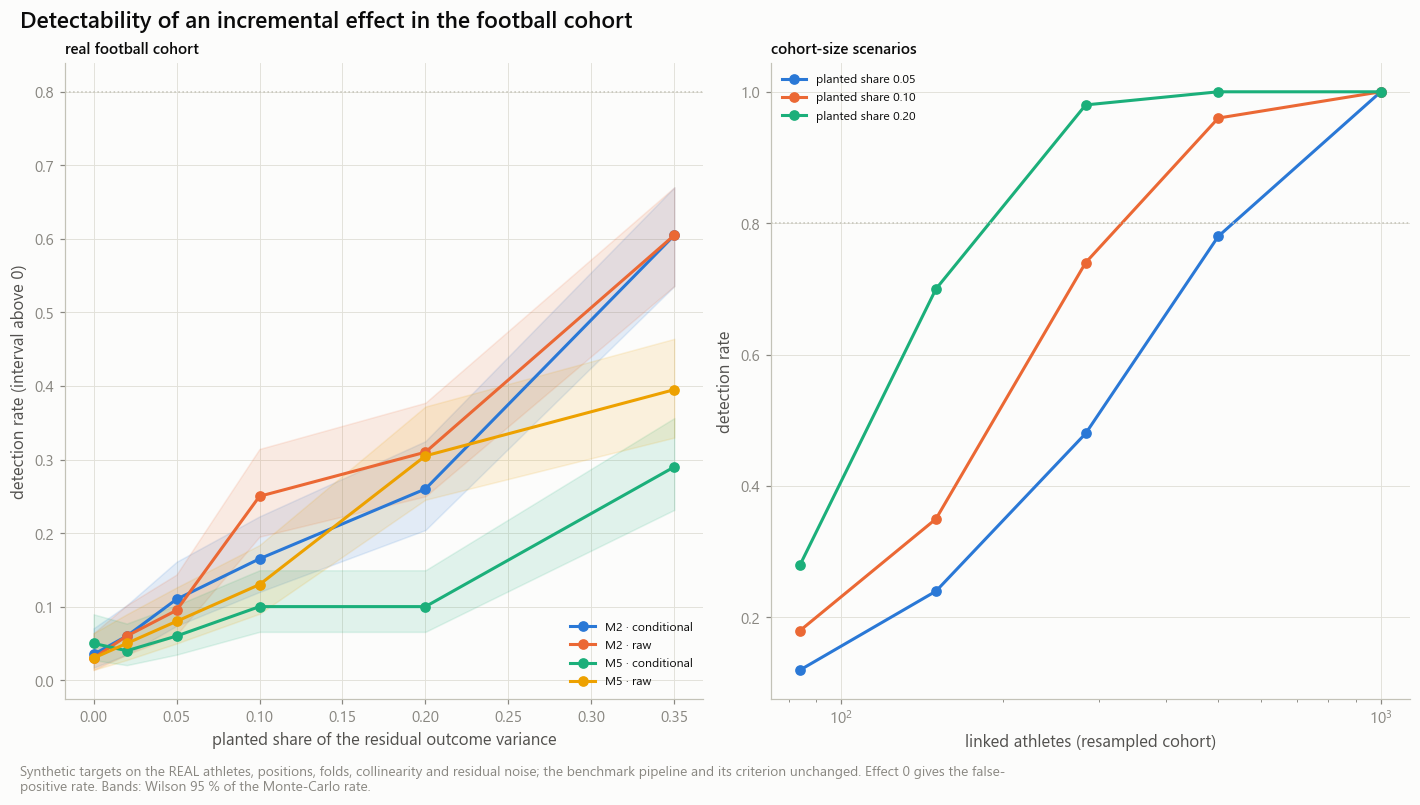

In [10]:
tp.assert_complete(sim_summary)                               # an incomplete simulation is never summarised
scen, null, mde = tp.scenario_table(reps, sim_plan), tp.null_table(reps), None
mde = tp.mde_table(scen, pc)
if controls.save_tables:
    for df, c in ((reps, tp.REPLICATES), (scen, tp.SCENARIOS), (null, tp.NULL), (mde, tp.MDE)):
        store.write(df, c, '08B3', PROV)
rel_y = (m2.get('outcome_reliability') or {}).get('rel_sb')
atten = tp.attenuation_grid([0.2, 0.3, 0.5], [0.5, 0.7, 0.8, 0.95], sorted({0.5, 0.6, 0.7, round(rel_y, 2) if rel_y else 0.7, 0.9}))
with pl.Config(tbl_rows=-1, tbl_width_chars=240, fmt_str_lengths=120):
    display(null.filter(pl.col('scope') == 'ALL'))
    display(mde.filter(pl.col('scope') == 'ALL'))
    display(scen.filter((pl.col('study') == 'sample_size') & (pl.col('scope') == 'ALL')).select('candidate', 'effect', 'n_athletes', 'n_replicates', 'power', 'power_lower', 'power_upper', 'mean_relative'))
    display(atten.head(20))
store.show(ff.fig_power(scen, pc.target_power), 'AM08B3_02_detectability_power_and_sample_size', {'scenarios': scen}, publication=True,
           source='transfer_power_scenarios (football cohort)', n=f'{DD.n} athletes; {int(sim_plan["replicates"].sum())} synthetic replicates')

## 3 · Permutation diagnostics

The null distributions computed in 08B.2, shown again with their budgets. Each draw is a **full refit** under a shuffled design (linkage) or shuffled labels (outcome) inside position groups. Shuffling fixed out-of-fold predictions is not a substitute and is not used anywhere.

target_id,model,reference,mode,observed,null_mean,null_sd,null_q95,p_value,n_perm,n_planned,complete,signature
str,str,str,str,f64,f64,f64,f64,f64,i64,i64,bool,str
"""FO01.S0""","""M2""","""M1""","""linkage""",-0.000685,-0.001684,0.003348,0.002488,0.345309,500,500,true,"""42193930858b28cf"""
"""FO01.S0""","""M2""","""M1""","""outcome""",-0.000685,-0.000349,0.004068,0.003333,0.820896,200,200,true,"""00083d54a479a305"""
"""FO01.S0""","""M5""","""M1""","""linkage""",-0.010811,-0.003651,0.006177,0.004112,0.885572,200,200,true,"""39eb42a522c5f20b"""


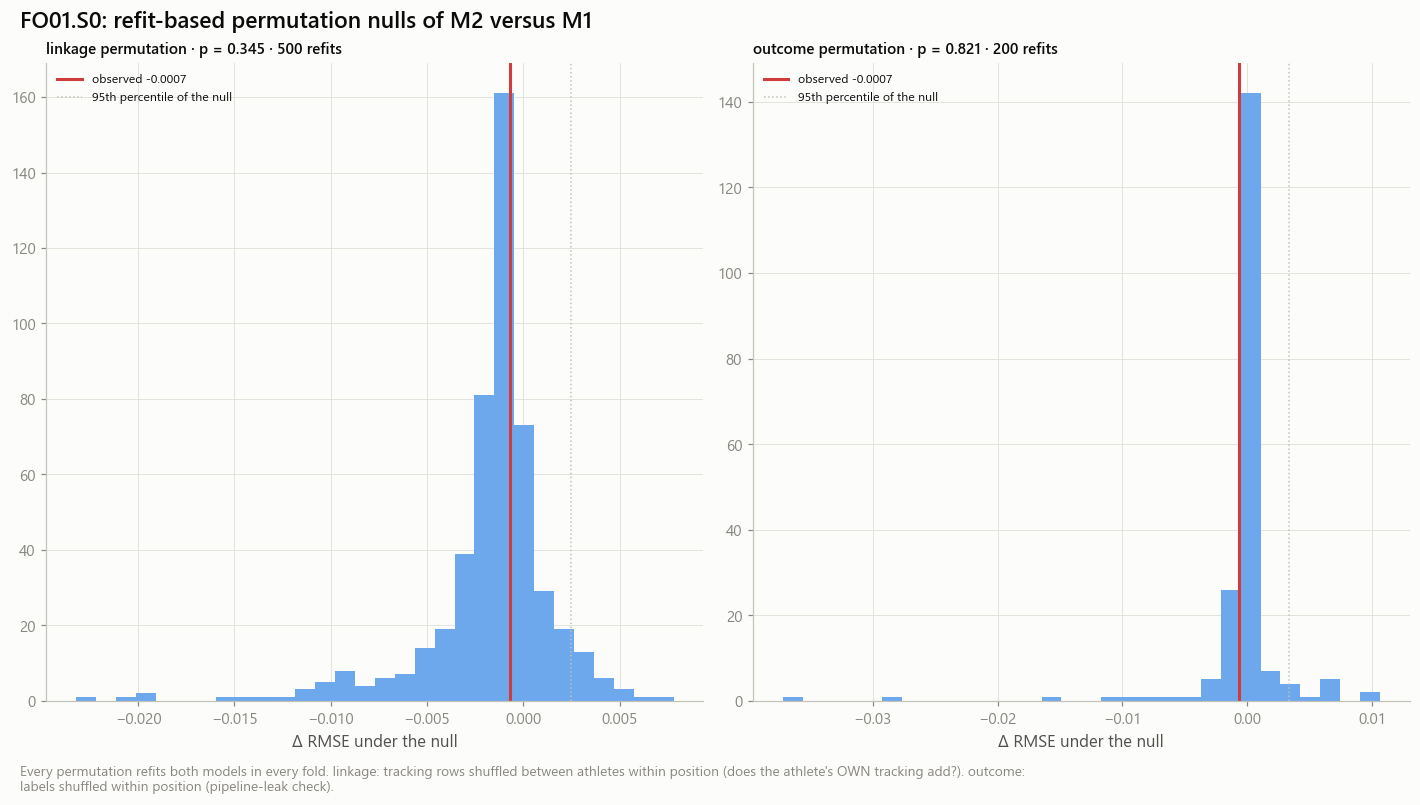

In [11]:
with pl.Config(tbl_rows=-1, tbl_width_chars=220):
    display(perm)
incomplete = perm.filter(~pl.col('complete'))
if incomplete.height:
    print(f'WARNING: {incomplete.height} permutation run(s) of 08B.2 are incomplete — rerun the permutation cell of 08B.2 (it resumes).')
store.show(ff.fig_null(perm_draws, perm.filter((pl.col('target_id') == PRIMARY) & (pl.col('model') == P0) & (pl.col('reference') == P1)),
                       f'{PRIMARY}: refit-based permutation nulls of {P0} versus {P1}'),
           'AM08B3_03_permutation_diagnostics', {'permutation': perm}, source='football_transfer_permutation_draws', n=f'{DD.n} athletes')

## 4 · Robustness reading

Six readings of the primary comparison, **kept apart**: point estimate · statistical evidence · practical importance · cohort limitations and sensitivities · detectability · measurement reliability · outcome validity. They are not collapsed into one verdict.

23:41:14 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B3] football_transfer_robustness_reading: 7 rows → warehouse/gold/advanced_movement/football_v1/football_transfer_robustness_reading.parquet


aspect,finding,evidence
str,str,str
"""point_estimate""","""Δ RMSE -0.0007 (-0.18 % of the reference error)""","""M2 versus M1 on 84 held-out athletes"""
"""statistical_evidence""","""interval includes 0""","""95 % athlete bootstrap [-0.0093, +0.0082]; linkage permutation p 0.345"""
"""practical_importance""","""below the 2% margin""","""heuristic margin of Milestone 06; a scouting use would need a decision study, not an error ratio"""
"""cohort_limitations""","""84 athletes (TE 20 · WR 64); 2 of 8 sensitivity analyses have a positive point estimate""","""one linked cohort; subgroup rows are scored from the pooled fit; no independent TE model"""
"""detectability""","""M2: smallest detectable planted share not reached in the grid (max power 0.60); M5: smallest detectable planted share not reached in the grid (max power 0.29)""","""planted-signal simulation on the real cohort, folds and collinearity (08B.3)"""
"""measurement_reliability""","""odd / even reliability of the outcome 0.74""","""an unreliable outcome attenuates every association; the ceiling is shown in the attenuation table"""
"""outcome_validity""","""source class PROVISIONAL""","""an interaction outcome with inferred semantics supports an exploratory association at most"""


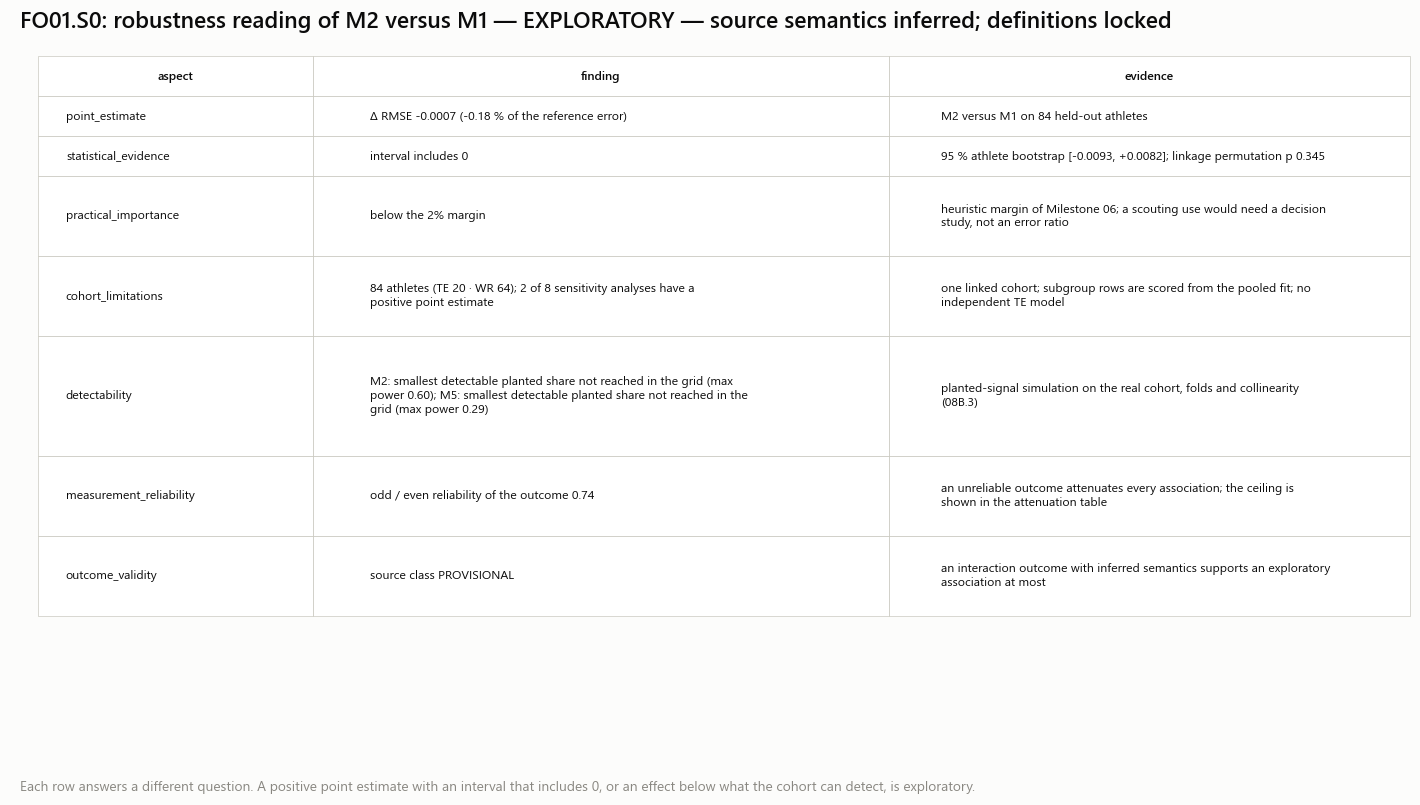

In [12]:
h = hyp_table.filter((pl.col('target_id') == PRIMARY) & (pl.col('role') == 'primary'))
source_class = fr.targets_of(REGISTRY, 'primary')[0]['source_confidence']
robust = save(ft.robustness_reading(h.row(0, named=True) if h.height else None, paired_sens, mde, rel_y, source_class, DD.n, m2['position_counts'], ftc), ft.ROBUST)
with pl.Config(fmt_str_lengths=260, tbl_rows=-1, tbl_width_chars=300):
    display(robust)
store.show(ff.fig_reading(robust, ['aspect', 'finding', 'evidence'], f'{PRIMARY}: robustness reading of {P0} versus {P1} — {BRANCH["label"]}',
                          'Each row answers a different question. A positive point estimate with an interval that includes 0, or an effect below what the cohort can '
                          'detect, is exploratory.', [0.2, 0.42, 0.38]),
           'AM08B3_04_robustness_reading', {'reading': robust}, source='football_transfer_robustness_reading', n=f'{DD.n} athletes')
if controls.save_tables:
    m_all = mde.filter((pl.col('study') == 'power') & (pl.col('scope') == 'ALL'))
    store.write_json('football_robustness_manifest', {
        'experiment_version': EXPERIMENT_VERSION, 'finished_at': utc_now(), 'registry_hash': REGISTRY['version_hash'], 'branch': BRANCH, 'primary': PRIMARY,
        'n_primary': DD.n, 'sensitivities': plan.to_dicts(), 'simulation': sim_summary, 'simulation_config': pc.params(), 'mde': m_all.to_dicts(),
        'null': null.filter(pl.col('scope') == 'ALL').to_dicts(), 'provenance': PROV})

## 5 · Reading

- If the smallest detectable effect is larger than any plausible incremental effect, a null result of 08B.2 says *not detectable here*, not *absent*.
- If the false-positive rate at f = 0 is near its nominal value, a positive result of 08B.2 is not an artefact of the pipeline — it is still one cohort and, under an exploratory branch, an exploratory association.
- The cohort-size scenarios state what a future study needs; they are the basis of the *what should be tested with future data* section of the final report.

**Send back:** the sensitivity plan and forest table, the null and MDE tables, the cohort-size table, the robustness reading, figures `AM08B3_01`, `02`.

**Next:** `08b4_incremental_movement_information.ipynb` (independent of the football branch).